In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
SPEAKERS = ["bdl", "slt"]  # bdl - источник (мужской), slt - цель (женский)

In [2]:
def read_prompts(spk):
    path = RAW / f"cmu_us_{spk}_arctic" / "etc" / "txt.done.data"
    out = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        m = re.match(r'\(\s*(\S+)\s+"(.*)"\s*\)\s*$', line.strip())
        if m:
            out[m.group(1)] = m.group(2)
    return out

def audio_table(spk):
    rows = []
    for p in sorted((RAW / f"cmu_us_{spk}_arctic" / "wav").glob("*.wav")):
        info = sf.info(p)  # читает только заголовок, не весь файл
        rows.append(dict(speaker=spk, utt=p.stem, sr=info.samplerate,
                         channels=info.channels, subtype=info.subtype,
                         dur_s=info.duration))
    return pd.DataFrame(rows)

df = pd.concat([audio_table(s) for s in SPEAKERS], ignore_index=True)
prompts = {s: read_prompts(s) for s in SPEAKERS}
print({s: len(prompts[s]) for s in SPEAKERS})
df.groupby("speaker").agg(
    n=("utt", "count"),
    sr=("sr", lambda x: sorted(x.unique())),
    channels=("channels", lambda x: sorted(x.unique())),
    subtype=("subtype", lambda x: sorted(x.unique())),
    total_min=("dur_s", lambda x: round(x.sum() / 60, 1)),
)

{'bdl': 1131, 'slt': 1132}


,n,sr,channels,subtype,total_min
speaker,,,,,
bdl,1132,[16000],[1],[PCM_16],51.0
slt,1132,[16000],[1],[PCM_16],56.6


In [3]:
ids = {s: set(df.loc[df.speaker == s, "utt"]) for s in SPEAKERS}
common = ids["bdl"] & ids["slt"]
print("только bdl:", len(ids["bdl"] - ids["slt"]),
      "| только slt:", len(ids["slt"] - ids["bdl"]),
      "| общих:", len(common))
print("одинаковый текст у общих:",
      sum(prompts["bdl"].get(u) == prompts["slt"].get(u) for u in common),
      "из", len(common))
print("wav без текста:", {s: len(ids[s] - set(prompts[s])) for s in SPEAKERS})

только bdl: 0 | только slt: 0 | общих: 1132
одинаковый текст у общих: 1131 из 1132
wav без текста: {'bdl': 1, 'slt': 0}


          count  mean   std   min   25%   50%   75%   max
speaker                                                  
bdl      1132.0   2.7  0.77  0.97  2.14  2.65  3.23  5.73
slt      1132.0   3.0  0.73  1.16  2.47  2.97  3.47  5.35


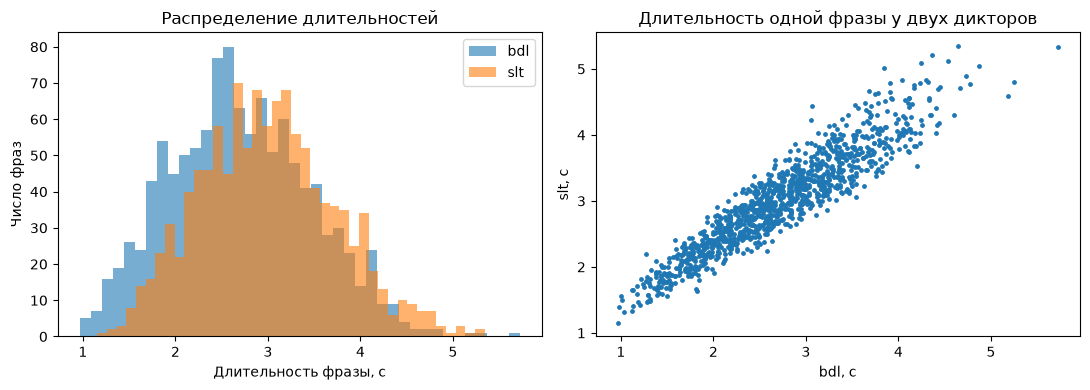

корреляция длительностей: 0.932


In [4]:
print(df.groupby("speaker")["dur_s"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for s in SPEAKERS:
    axes[0].hist(df.loc[df.speaker == s, "dur_s"], bins=40, alpha=0.6, label=s)
axes[0].set(xlabel="Длительность фразы, с", ylabel="Число фраз",
            title="Распределение длительностей")
axes[0].legend()

wide = df.pivot(index="utt", columns="speaker", values="dur_s").dropna()
axes[1].scatter(wide["bdl"], wide["slt"], s=6)
axes[1].set(xlabel="bdl, с", ylabel="slt, с",
            title="Длительность одной фразы у двух дикторов")
plt.tight_layout()
plt.savefig(DOCS / "durations.png", dpi=150)
plt.show()
print("корреляция длительностей:", round(wide.corr().iloc[0, 1], 3))

In [5]:
def wav_stats(spk):
    rows = []
    for p in sorted((RAW / f"cmu_us_{spk}_arctic" / "wav").glob("*.wav")):
        x, sr = sf.read(p, dtype="float32")
        if x.ndim > 1:
            x = x[:, 0]  # предположение: речь в первом канале, проверим по результатам
        rows.append(dict(speaker=spk, utt=p.stem, peak=float(np.abs(x).max()),
                         rms=float(np.sqrt(np.mean(x ** 2))),
                         has_nan=bool(np.isnan(x).any())))
    return pd.DataFrame(rows)

q = pd.concat([wav_stats(s) for s in SPEAKERS], ignore_index=True)
print(q.groupby("speaker")[["peak", "rms"]].describe().round(3).T)
print("NaN:", int(q["has_nan"].sum()), "| пик >= 0.999:", int((q["peak"] >= 0.999).sum()))
df.merge(q, on=["speaker", "utt"]).to_csv(DOCS / "dataset_stats.csv", index=False)

speaker          bdl       slt
peak count  1132.000  1132.000
     mean      0.650     0.650
     std       0.000     0.000
     min       0.650     0.650
     25%       0.650     0.650
     50%       0.650     0.650
     75%       0.650     0.650
     max       0.650     0.650
rms  count  1132.000  1132.000
     mean      0.086     0.115
     std       0.015     0.019
     min       0.042     0.057
     25%       0.076     0.103
     50%       0.086     0.115
     75%       0.096     0.129
     max       0.138     0.177
NaN: 0 | пик >= 0.999: 0


In [6]:
raw = (RAW / "cmu_us_bdl_arctic" / "etc" / "txt.done.data").read_text(encoding="utf-8").splitlines()
missing = sorted(ids["bdl"] - set(prompts["bdl"]))
print("строк в файле:", len(raw), "| wav без текста:", missing)
for u in missing:
    print("bdl:", [l for l in raw if u in l])
    print("slt:", prompts["slt"].get(u))
print("не распознаны шаблоном:", [l for l in raw if not re.match(r'\(\s*(\S+)\s+"(.*)"\s*\)\s*$', l.strip())])

строк в файле: 1131 | wav без текста: ['arctic_a0507']
bdl: []
slt: In short, my joyous individualism was dominated by the orthodox bourgeois ethics.
не распознаны шаблоном: []
